In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import dask.dataframe as dd

# **Creating Dataframe**

In [6]:
sector_df = pd.read_csv('/content/drive/MyDrive/RND/OperationsBridge/flightsector2.csv', low_memory=False)
print(sector_df.head())

   BOOKING_ID PRODUCT_CODE  ITEM_NO  SECTOR_NO  LEG_NO BOOKED_DATE DIRECTION  \
0       10006          FLT      1.0        1.0     1.0  2018-11-15         O   
1       10007          FLT      1.0        2.0     2.0  2018-11-15         I   
2       10007          FLT      1.0        1.0     1.0  2018-11-15         O   
3       10006          FLT      1.0        2.0     1.0  2018-11-15         O   
4       10006          FLT      1.0        3.0     2.0  2018-11-15         I   

  AIRLINE  DEP  DES   DEP_DATE   DES_DATE BOOKING_CLASS     CABIN_CLASS  \
0      LH  LHR  MUC  01-SEP-19  01-SEP-19             K         Economy   
1      BA  DEL  LHR  29-AUG-19  29-AUG-19             V         Economy   
2      BA  LHR  DEL  20-AUG-19  20-AUG-19             N         Economy   
3      LH  MUC  DEL  01-SEP-19  01-SEP-19             K         Economy   
4      LH  DEL  FRA  09-SEP-19  09-SEP-19             N  PremiumEconomy   

  OPERATING_AIRLINE  
0                LH  
1                BA  
2 

In [7]:
sector_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3818178 entries, 0 to 3818177
Data columns (total 15 columns):
BOOKING_ID           int64
PRODUCT_CODE         object
ITEM_NO              float64
SECTOR_NO            float64
LEG_NO               float64
BOOKED_DATE          object
DIRECTION            object
AIRLINE              object
DEP                  object
DES                  object
DEP_DATE             object
DES_DATE             object
BOOKING_CLASS        object
CABIN_CLASS          object
OPERATING_AIRLINE    object
dtypes: float64(3), int64(1), object(11)
memory usage: 437.0+ MB


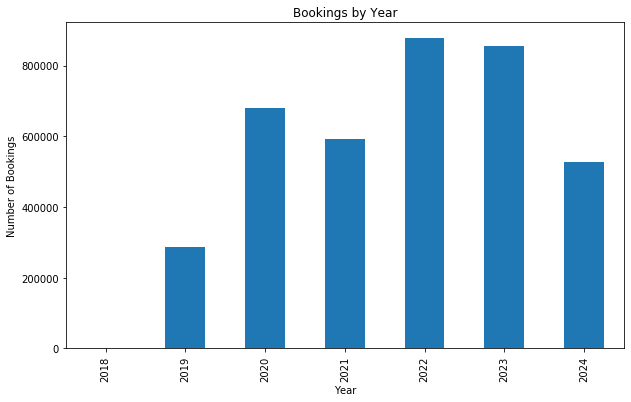

In [8]:

sector_df['BOOKED_DATE'] = pd.to_datetime(sector_df['BOOKED_DATE'])
bookings_by_year = sector_df.groupby(sector_df['BOOKED_DATE'].dt.year)['BOOKING_ID'].count()

plt.figure(figsize=(10, 6))
bookings_by_year.plot(kind='bar')
plt.xlabel('Year')
plt.ylabel('Number of Bookings')
plt.title('Bookings by Year')
plt.show()


2018 has only 40 records hence why its not shown in the graph

In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

# Define a function to get the season based on the month
def get_season(month):
  if month in [12, 1, 2]:
    return 'Winter'
  elif month in [3, 4, 5]:
    return 'Spring'
  elif month in [6, 7, 8]:
    return 'Summer'
  else:
    return 'Autumn'

# Apply the get_season function to the 'BOOKED_DATE' column to create a new 'Season' column
sector_df['Season'] = sector_df['BOOKED_DATE'].dt.month.apply(get_season)

# Group the data by year and season and count the number of bookings
bookings_by_season = sector_df.groupby([sector_df['BOOKED_DATE'].dt.year, 'Season'])['BOOKING_ID'].count().reset_index()

# Create the interactive bar chart
fig = px.bar(bookings_by_season, x='BOOKED_DATE', y='BOOKING_ID', color='Season',
             title='Bookings by Season and Year',
             labels={'BOOKED_DATE': 'Year', 'BOOKING_ID': 'Number of Bookings'})
fig.show()

ModuleNotFoundError: No module named 'plotly'

Note : On average winter has the most number of bookings

In [ ]:
# prompt: display the number of bookings by 'CABIN_CLASS' in a pie chart. keep the labels seperately. make it an interactive pie chart

import plotly.express as px

def standardize_string(x):
  if isinstance(x, str):
    return x.lower().strip()
  else:
    return x

# Apply the function to all columns in the DataFrame
sector_df = sector_df.applymap(standardize_string)

bookings_by_cabin = sector_df.groupby('CABIN_CLASS')['BOOKING_ID'].count()

fig = px.pie(bookings_by_cabin,
             values=bookings_by_cabin.values,
             names=bookings_by_cabin.index,
             title='Bookings by Cabin Class')
fig.update_traces(textposition='outside', textinfo='percent+label')
fig.show()


In [ ]:

print(sector_df['CABIN_CLASS'].unique())


['economy' 'premiumeconomy' 'first' 'business' nan 'executive' ''
 'economy with restrictions' 'economy without restrictions']


In [ ]:

# Check for missing values (NaN) in the entire DataFrame
missing_values = sector_df.isnull().sum()
print(missing_values)


BOOKING_ID               0
PRODUCT_CODE             0
ITEM_NO                  0
SECTOR_NO                0
LEG_NO                   0
BOOKED_DATE              0
DIRECTION                0
AIRLINE                  0
DEP                      0
DES                      0
DEP_DATE                 0
DES_DATE                 0
BOOKING_CLASS         1112
CABIN_CLASS           8286
OPERATING_AIRLINE    97659
Season                   0
dtype: int64


In [ ]:
bookings_df = pd.read_csv('/content/drive/MyDrive/RND/OperationsBridge/flightbookings2.csv', low_memory=False)

In [ ]:
print(bookings_df.head())

   BOOKING_ID PRODUCT_CODE  ITEM_NO  BOOKING_STATUS  OPTION_STATUS  \
0       10006          FLT      1.0          1000.0          400.0   
1       10007          FLT      1.0          1000.0          400.0   
2       10012          FLT      1.0          1000.0          400.0   
3       10013          FLT      1.0          1000.0          400.0   
4       10014          FLT      1.0          1000.0          400.0   

   BOOKING_ITEM_STATUS BOOKED_DATE  FROM_DATE  ADULT  CHILD  ...  CRS  \
0               1000.0  2018-11-15  01-SEP-19    2.0    0.0  ...  TPU   
1               1000.0  2018-11-15  20-AUG-19    2.0    0.0  ...  TPU   
2               1000.0  2018-11-16  20-AUG-19    2.0    0.0  ...  TPU   
3               1000.0  2018-11-19  01-JAN-19    2.0    0.0  ...  TPU   
4               1000.0  2018-11-19  19-OCT-19    2.0    0.0  ...  TPU   

   ADT_COST  CHD_COST  INF_COST ADT_TAX_COST  CHD_TAX_COST  INF_TAX_COST  \
0      83.0       0.0       0.0       329.54           0.0      

In [ ]:
print(bookings_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1345474 entries, 0 to 1345473
Data columns (total 29 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   BOOKING_ID              1345474 non-null  int64  
 1   PRODUCT_CODE            1345474 non-null  object 
 2   ITEM_NO                 1345474 non-null  float64
 3   BOOKING_STATUS          1345474 non-null  float64
 4   OPTION_STATUS           1345474 non-null  float64
 5   BOOKING_ITEM_STATUS     1345474 non-null  float64
 6   BOOKED_DATE             1345474 non-null  object 
 7   FROM_DATE               1345474 non-null  object 
 8   ADULT                   1345474 non-null  float64
 9   CHILD                   1345474 non-null  float64
 10  INFANT                  1345474 non-null  float64
 11  PRICE                   1345474 non-null  float64
 12  COST                    1345474 non-null  float64
 13  COST_IN_CONTRACT        1345474 non-null  float64
 14  CU

In [ ]:
print(bookings_df.describe())

         BOOKING_ID       ITEM_NO  BOOKING_STATUS  OPTION_STATUS  \
count  1.345474e+06  1.345474e+06    1.345474e+06   1.345474e+06   
mean   1.577275e+05  7.082342e+00    1.116718e+03   3.430789e+02   
std    8.285312e+04  8.915967e+00    3.613520e+02   1.871620e+02   
min    1.000600e+04  1.000000e+00    1.000000e+03   2.000000e+02   
25%    8.575900e+04  2.000000e+00    1.000000e+03   2.000000e+02   
50%    1.596865e+05  4.000000e+00    1.000000e+03   2.000000e+02   
75%    2.292030e+05  9.000000e+00    1.000000e+03   6.000000e+02   
max    2.997500e+05  1.490000e+02    6.000000e+03   6.000000e+02   

       BOOKING_ITEM_STATUS         ADULT         CHILD        INFANT  \
count         1.345474e+06  1.345474e+06  1.345474e+06  1.345474e+06   
mean          4.474588e+03  2.329258e+00  1.952130e-01  2.449323e-02   
std           1.992399e+03  9.105552e-01  5.702492e-01  1.592077e-01   
min           1.000000e+02 -9.000000e+00  0.000000e+00  0.000000e+00   
25%           2.000000e+03 

In [ ]:
# prompt: check for missing values

# Check for missing values (NaN) in the entire DataFrame
missing_values = bookings_df.isnull().sum()
print(missing_values)


BOOKING_ID                    0
PRODUCT_CODE                  0
ITEM_NO                       0
BOOKING_STATUS                0
OPTION_STATUS                 0
BOOKING_ITEM_STATUS           0
BOOKED_DATE                   0
FROM_DATE                     0
ADULT                         0
CHILD                         0
INFANT                        0
PRICE                         0
COST                          0
COST_IN_CONTRACT              0
CURRENCY_IN_CONTRACT          0
TOTAL_COST                    0
TOTAL_PRICE                   0
TOTAL_COST_IN_CONTRACT        0
FARE_TYPE                 37355
CRS                       31579
ADT_COST                      0
CHD_COST                      0
INF_COST                      0
ADT_TAX_COST                  0
CHD_TAX_COST                  0
INF_TAX_COST                  0
ADT_PRICE                     0
CHD_PRICE                     0
INF_PRICE                     0
dtype: int64


# **Outlier Detection**

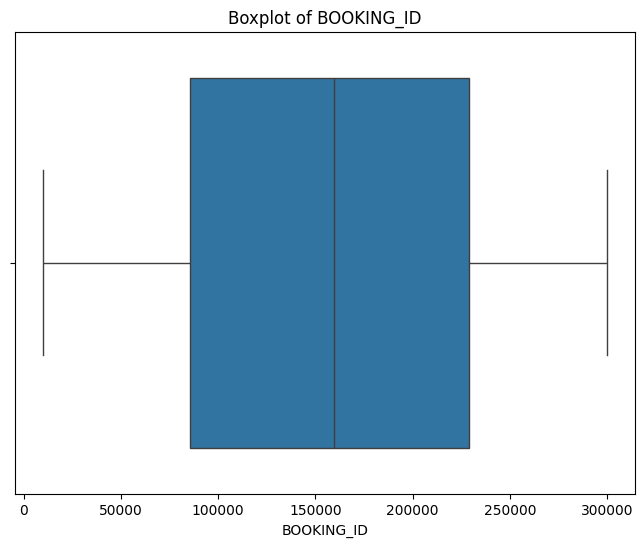

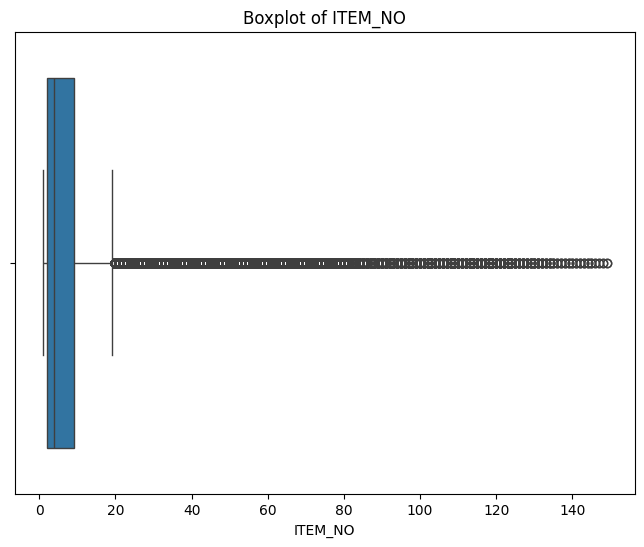

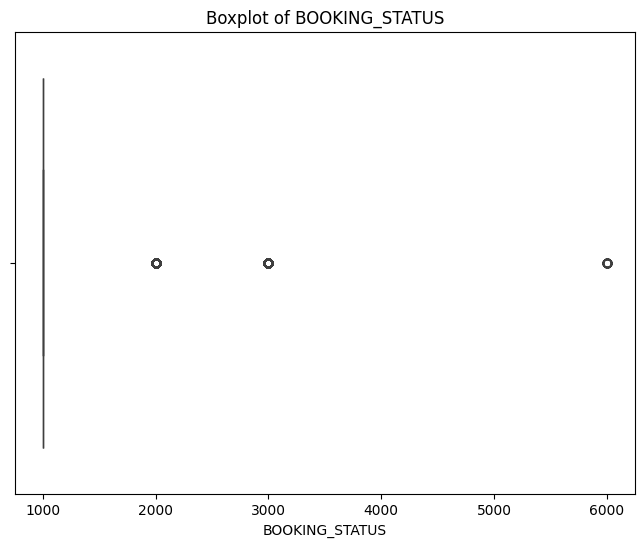

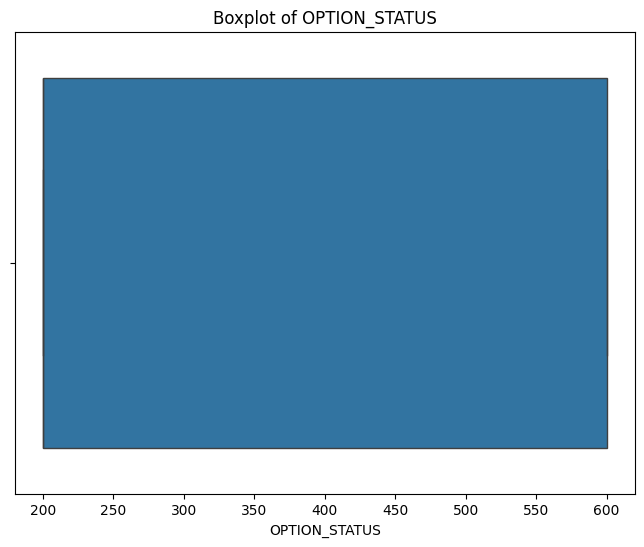

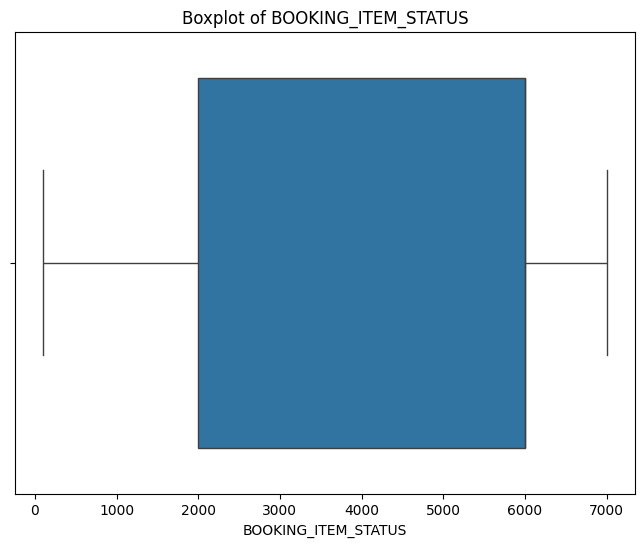

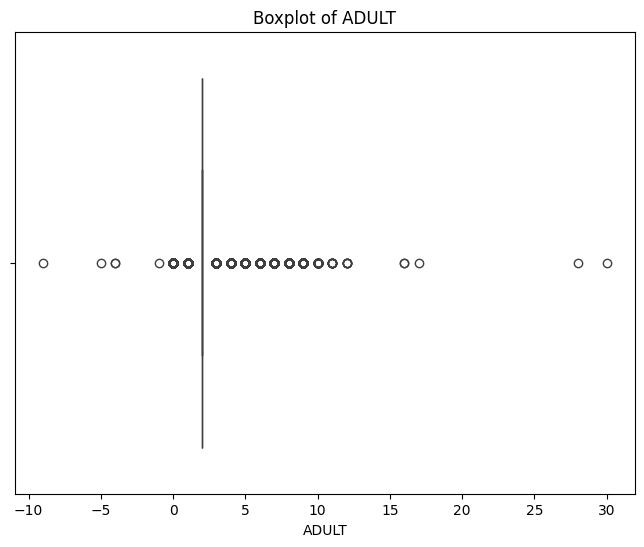

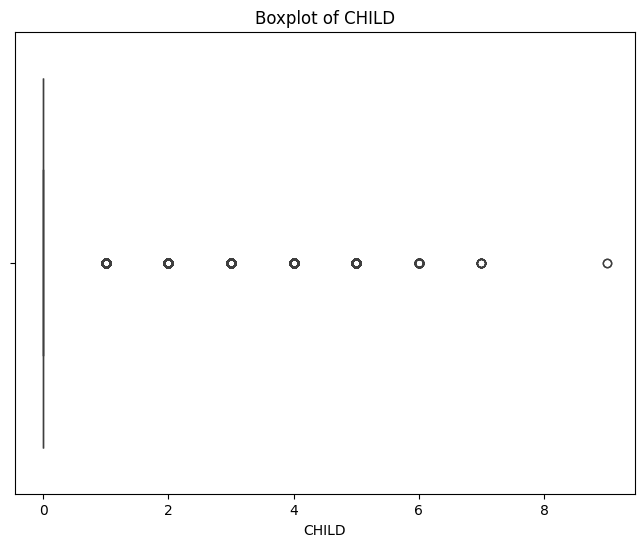

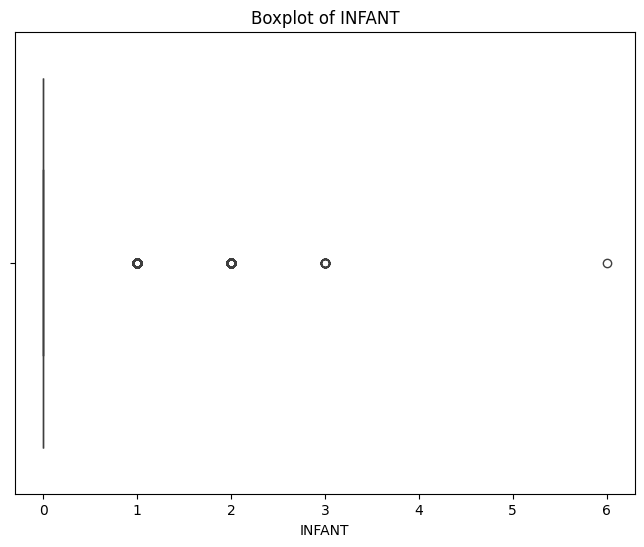

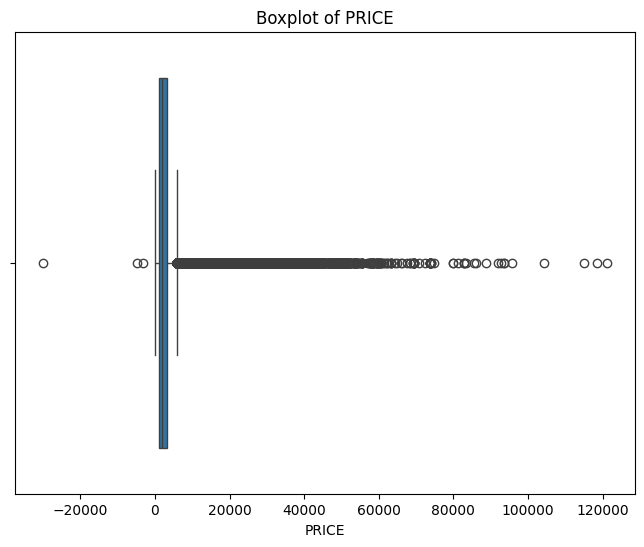

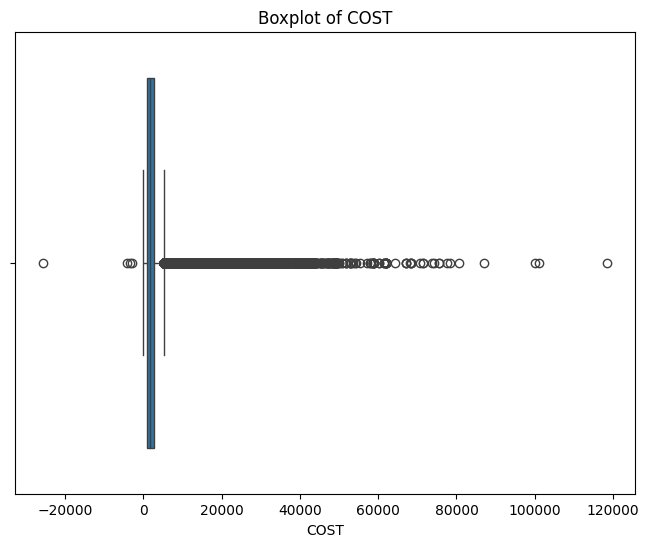

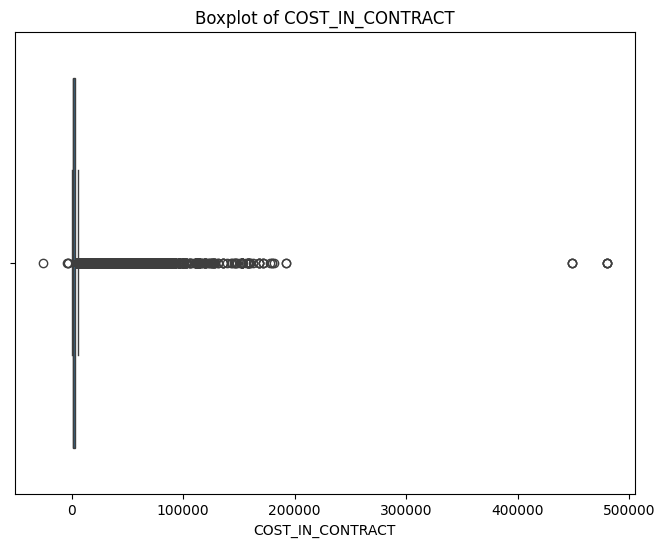

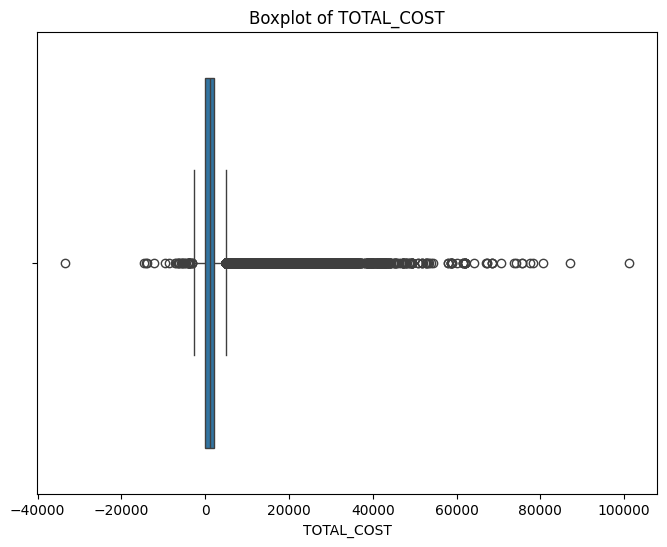

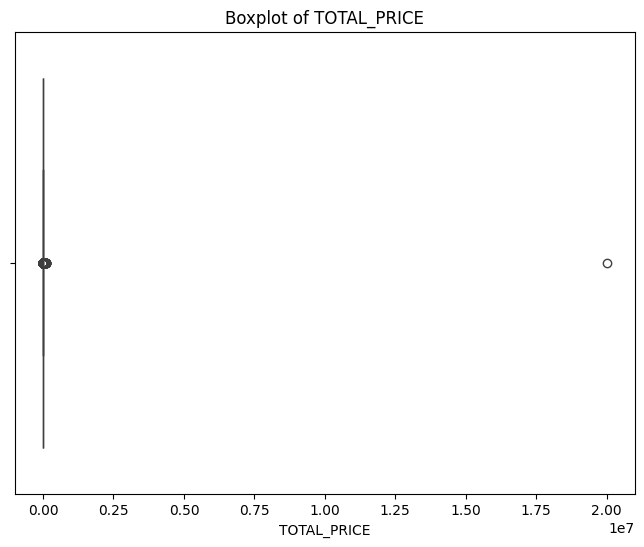

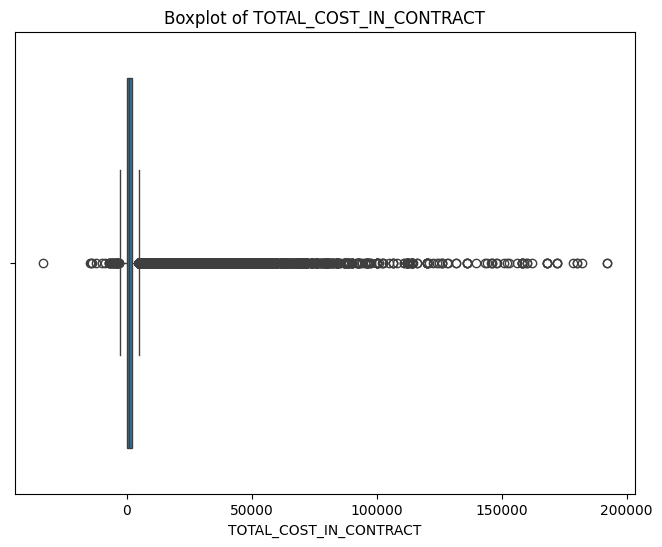

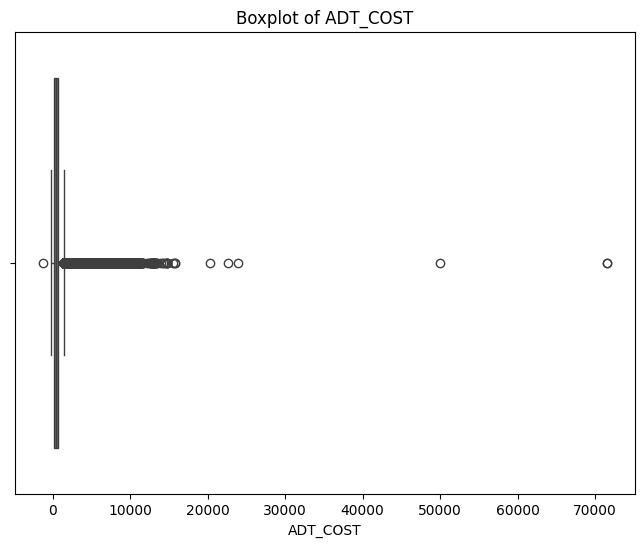

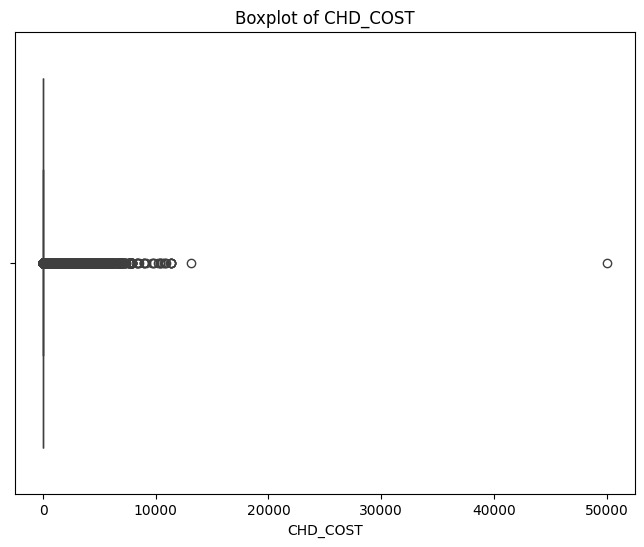

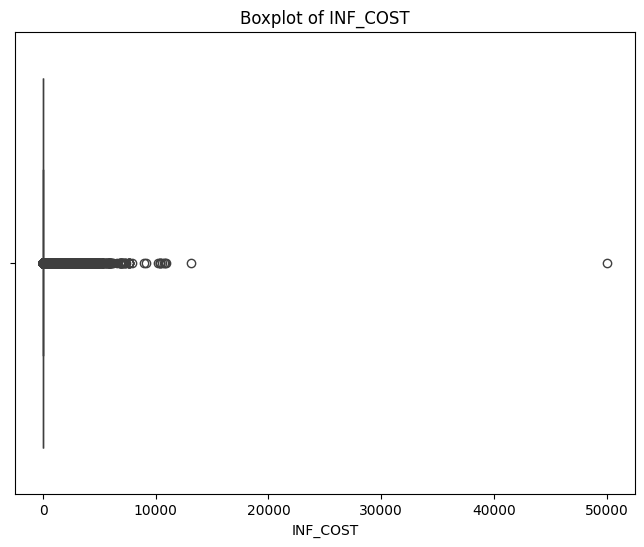

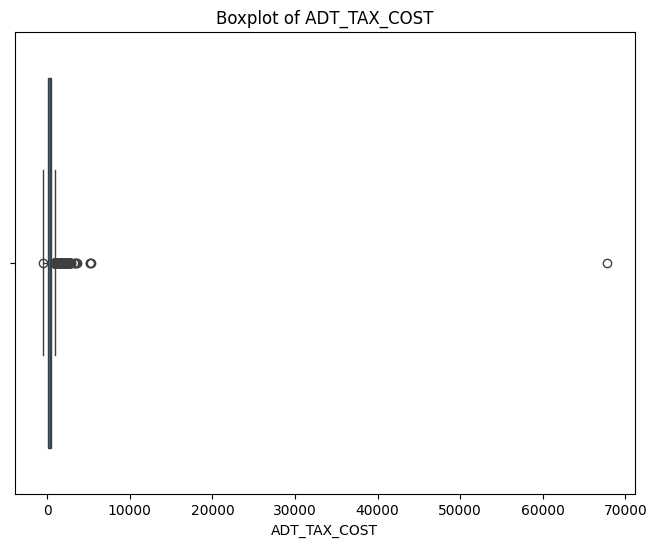

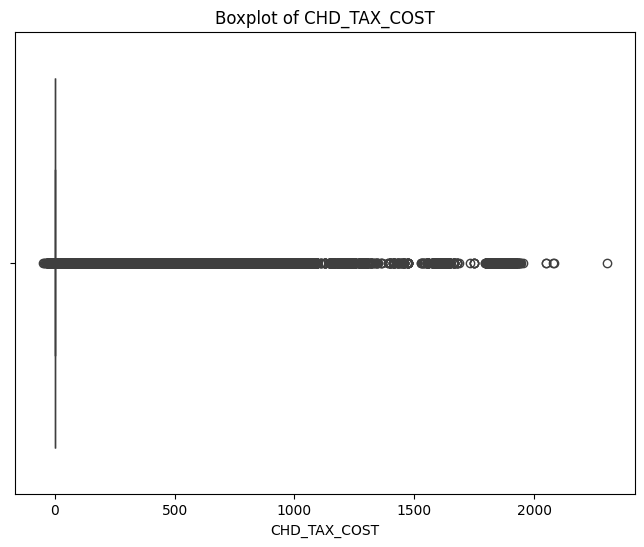

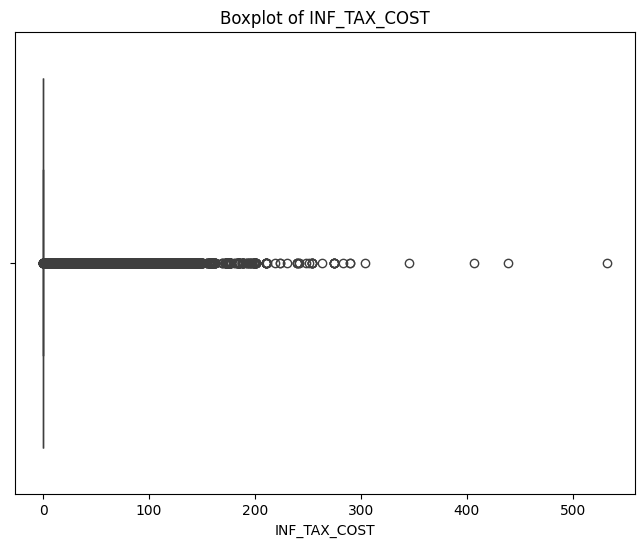

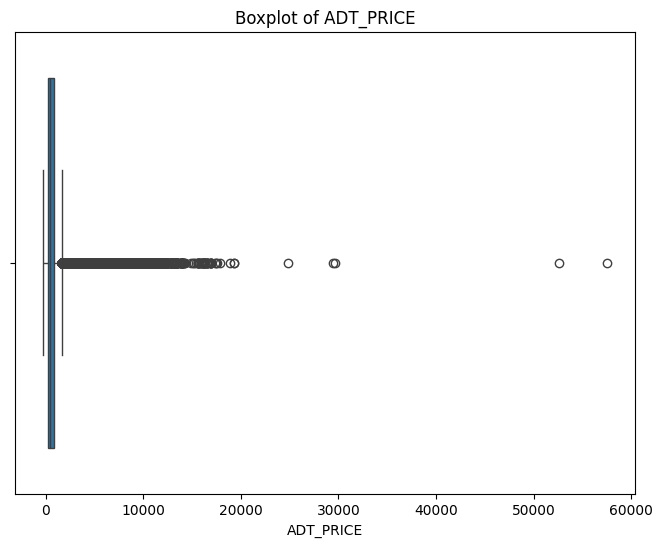

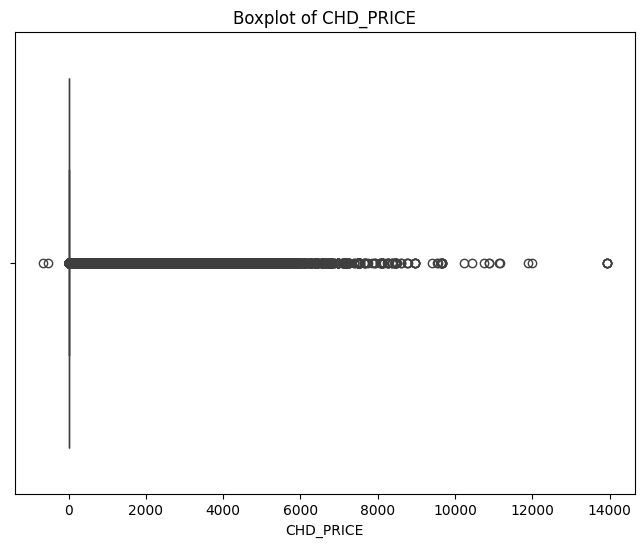

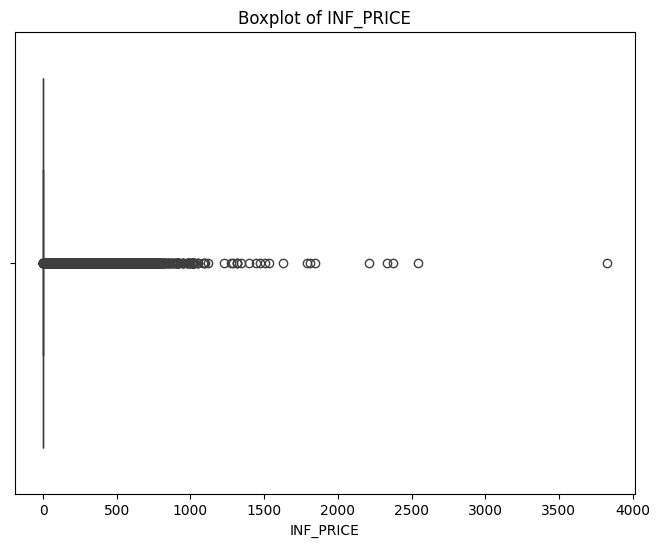

In [ ]:
# prompt: make boxplots to see outliers in each feature

import matplotlib.pyplot as plt
import seaborn as sns

# Iterate over numerical columns and create boxplots
for column in bookings_df.select_dtypes(include=['number']):
  plt.figure(figsize=(8, 6))
  sns.boxplot(x=bookings_df[column])
  plt.title(f'Boxplot of {column}')
  plt.show()


# **Trend and Seasonality Analysis**

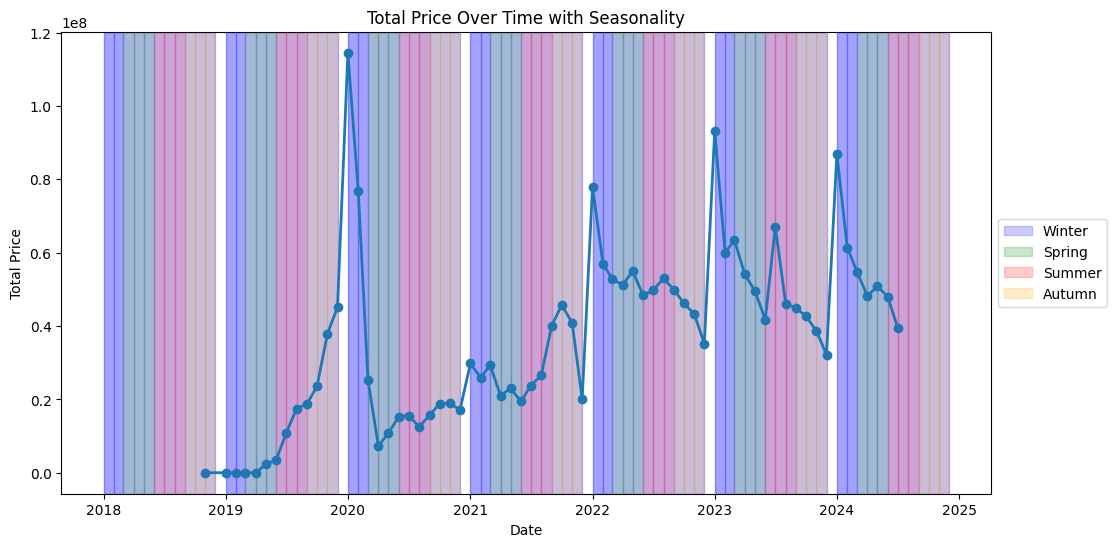

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert 'BOOKED_DATE' to datetime object
bookings_df['BOOKED_DATE'] = pd.to_datetime(bookings_df['BOOKED_DATE'])

# Extract year and month for grouping
bookings_df['Year'] = bookings_df['BOOKED_DATE'].dt.year
bookings_df['Month'] = bookings_df['BOOKED_DATE'].dt.month

# Calculate total price by year and month
bookings_by_time = bookings_df.groupby(['Year', 'Month'])['TOTAL_PRICE'].sum().reset_index()

# Create a new 'Date' column combining 'Year' and 'Month'
# This creates a datetime representation for plotting
bookings_by_time['Date'] = pd.to_datetime(bookings_by_time[['Year', 'Month']].assign(DAY=1))

# Plot time series with seasonality
plt.figure(figsize=(12, 6))

# Use the new 'Date' column for the x-axis
# Increase line width and add a marker for better visibility
plt.plot(bookings_by_time['Date'], bookings_by_time['TOTAL_PRICE'], linewidth=2, marker='o')

plt.xlabel('Date')
plt.ylabel('Total Price')
plt.title('Total Price Over Time with Seasonality')

# Highlight different seasons and add legend
seasons = {'Winter': 'blue', 'Spring': 'green', 'Summer': 'red', 'Autumn': 'orange'}
added_labels = set()

for year in bookings_by_time['Year'].unique():
  for month in range(1, 13):
    if month in [12, 1, 2]:
      label = 'Winter'
    elif month in [3, 4, 5]:
      label = 'Spring'
    elif month in [6, 7, 8]:
      label = 'Summer'
    else:
      label = 'Autumn'

    if label not in added_labels:
      plt.axvspan(pd.to_datetime(f"{int(year)}-{month}-01"), pd.to_datetime(f"{int(year)}-{month%12 +1}-01"),
                  color=seasons[label], alpha=0.2, label=label)
      added_labels.add(label)
    else:
      plt.axvspan(pd.to_datetime(f"{int(year)}-{month}-01"), pd.to_datetime(f"{int(year)}-{month%12 +1}-01"),
                  color=seasons[label], alpha=0.2)

# Add legend outside the plot area
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()

In winter bookings increase and the total price also has been increased

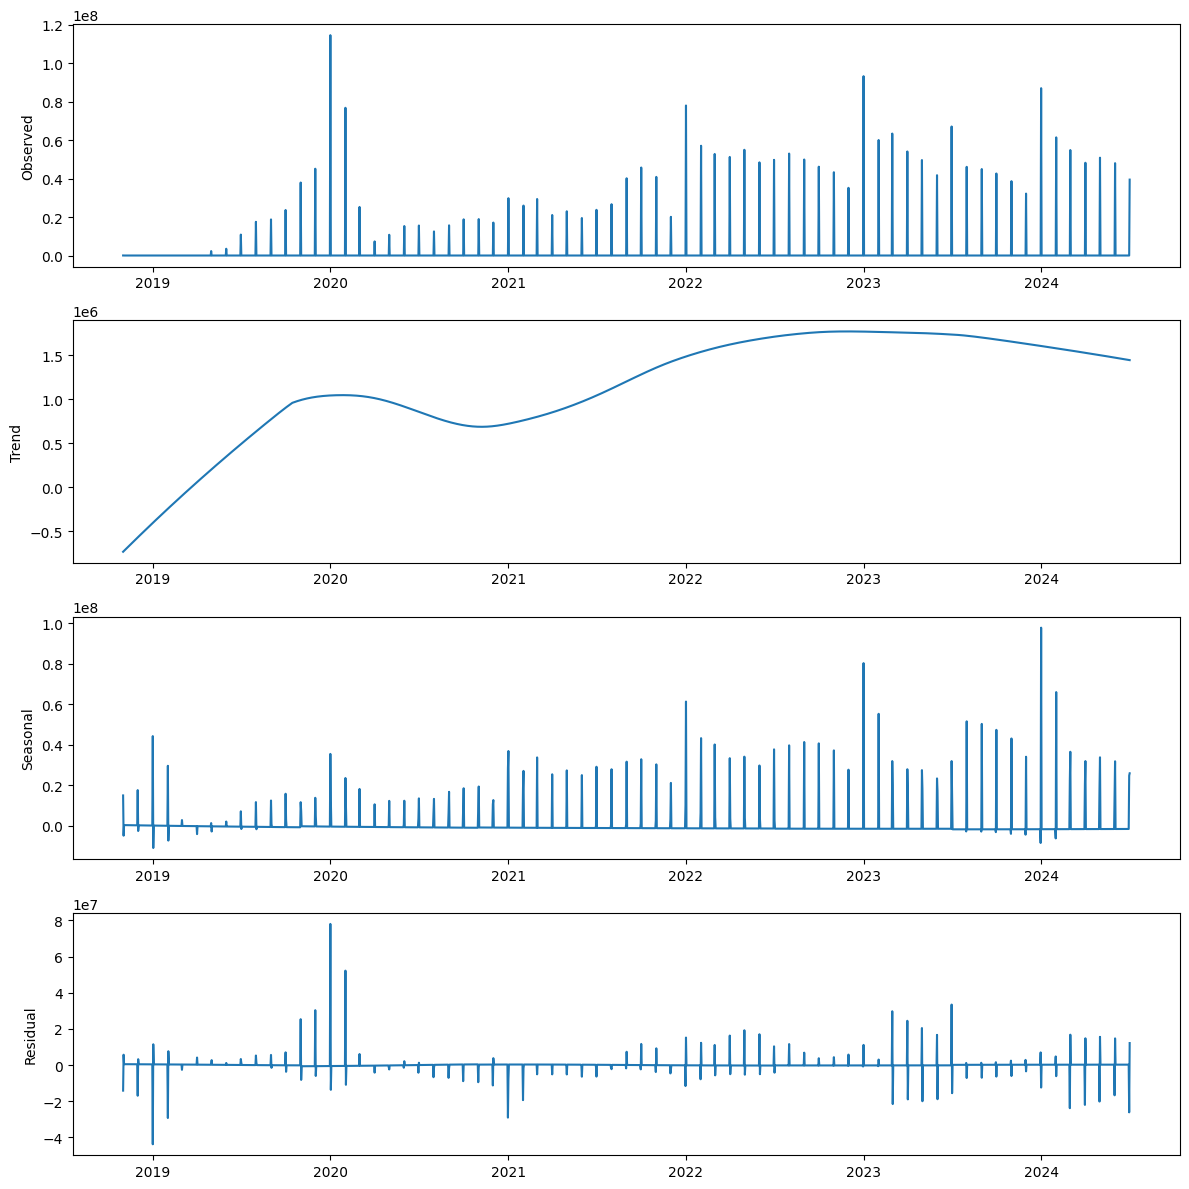

In [ ]:
# prompt: Decompose Time Series: Decompose the time series data into trend, seasonality, and residual components using methods like STL (Seasonal and Trend decomposition using Loess).

import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

# Resample to daily frequency for STL (it requires regular time intervals)
bookings_daily = bookings_by_time.set_index('Date').resample('D').sum().fillna(0)

# Decompose the time series
stl = STL(bookings_daily['TOTAL_PRICE'], period=365)  # Assuming yearly seasonality
res = stl.fit()

# Plot the decomposed components
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(12, 12))
ax1.plot(res.observed)
ax1.set_ylabel('Observed')
ax2.plot(res.trend)
ax2.set_ylabel('Trend')
ax3.plot(res.seasonal)
ax3.set_ylabel('Seasonal')
ax4.plot(res.resid)
ax4.set_ylabel('Residual')
plt.tight_layout()
plt.show()


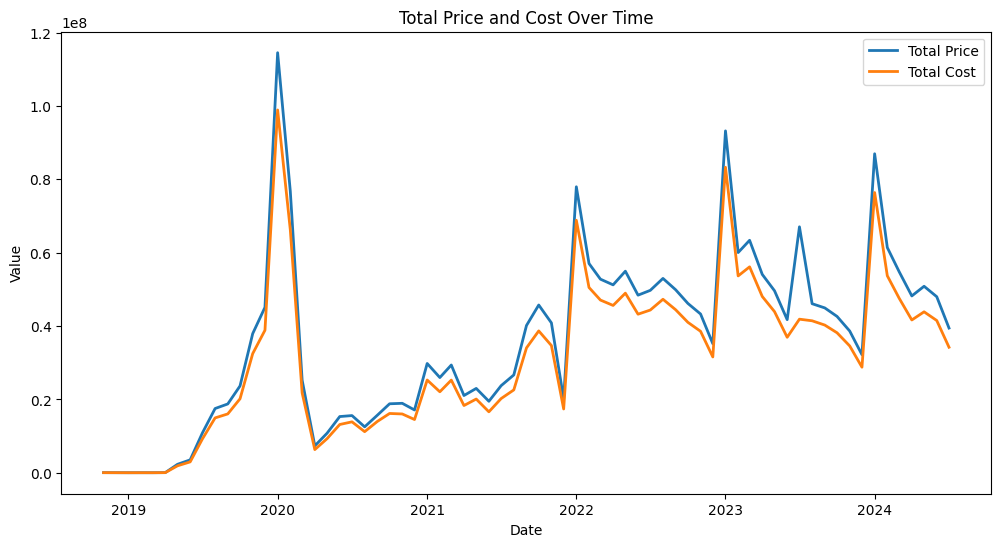

In [ ]:
# prompt: Total Price and Cost Over Time: Plot the total price (TOTAL_PRICE) and total cost (TOTAL_COST) over time to observe trends in pricing and cost.

import pandas as pd
import matplotlib.pyplot as plt
# Calculate total price and cost by year and month
price_cost_by_time = bookings_df.groupby(['Year', 'Month'])[['TOTAL_PRICE', 'TOTAL_COST']].sum().reset_index()

# Create a 'Date' column for plotting
price_cost_by_time['Date'] = pd.to_datetime(price_cost_by_time[['Year', 'Month']].assign(DAY=1))

# Plot total price and cost over time
plt.figure(figsize=(12, 6))
plt.plot(price_cost_by_time['Date'], price_cost_by_time['TOTAL_PRICE'], label='Total Price', linewidth=2)
plt.plot(price_cost_by_time['Date'], price_cost_by_time['TOTAL_COST'], label='Total Cost', linewidth=2)
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Total Price and Cost Over Time')
plt.legend()
plt.show()


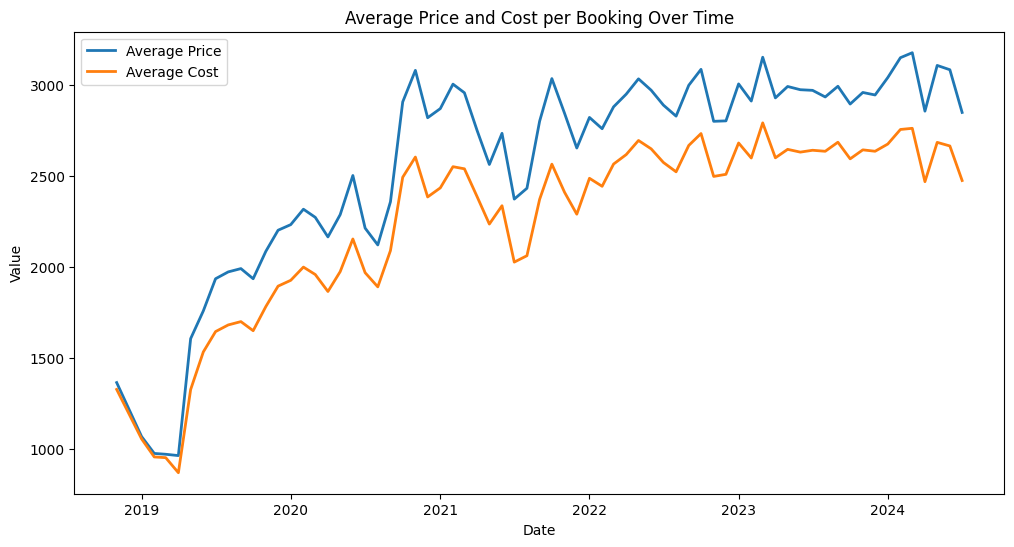

In [ ]:
# prompt: Price and Cost per Booking: Plot the average price (PRICE) and cost (COST) per booking over time.

import pandas as pd
import matplotlib.pyplot as plt
# Calculate average price and cost per booking
price_cost_per_booking = bookings_df.groupby(['Year', 'Month'])[['PRICE', 'COST']].mean().reset_index()

# Create a 'Date' column for plotting
price_cost_per_booking['Date'] = pd.to_datetime(price_cost_per_booking[['Year', 'Month']].assign(DAY=1))

# Plot average price and cost per booking over time
plt.figure(figsize=(12, 6))
plt.plot(price_cost_per_booking['Date'], price_cost_per_booking['PRICE'], label='Average Price', linewidth=2)
plt.plot(price_cost_per_booking['Date'], price_cost_per_booking['COST'], label='Average Cost', linewidth=2)
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Average Price and Cost per Booking Over Time')
plt.legend()
plt.show()


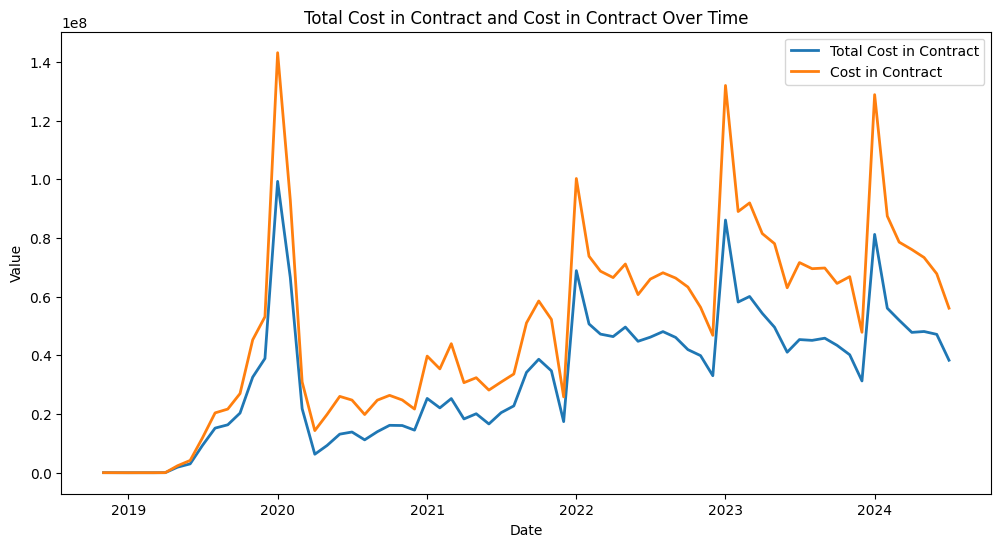

In [ ]:
# prompt: Price and Cost in Contract: Plot the total cost in contract (TOTAL_COST_IN_CONTRACT) and cost in contract (COST_IN_CONTRACT) over time.

import pandas as pd
import matplotlib.pyplot as plt
# Calculate total cost in contract and cost in contract by year and month
contract_cost_by_time = bookings_df.groupby(['Year', 'Month'])[['TOTAL_COST_IN_CONTRACT', 'COST_IN_CONTRACT']].sum().reset_index()

# Create a 'Date' column for plotting
contract_cost_by_time['Date'] = pd.to_datetime(contract_cost_by_time[['Year', 'Month']].assign(DAY=1))

# Plot total cost in contract and cost in contract over time
plt.figure(figsize=(12, 6))
plt.plot(contract_cost_by_time['Date'], contract_cost_by_time['TOTAL_COST_IN_CONTRACT'], label='Total Cost in Contract', linewidth=2)
plt.plot(contract_cost_by_time['Date'], contract_cost_by_time['COST_IN_CONTRACT'], label='Cost in Contract', linewidth=2)
plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Total Cost in Contract and Cost in Contract Over Time')
plt.legend()
plt.show()



In [ ]:

import plotly.graph_objects as go

# Count the number of bookings for each category
adult_count = bookings_df['ADULT'].sum()
child_count = bookings_df['CHILD'].sum()
infant_count = bookings_df['INFANT'].sum()

# Create a bar chart
fig = go.Figure(data=[
    go.Bar(name='Adults', x=['Passenger Type'], y=[adult_count]),
    go.Bar(name='Children', x=['Passenger Type'], y=[child_count]),
    go.Bar(name='Infants', x=['Passenger Type'], y=[infant_count])
])

# Update layout
fig.update_layout(
    title='Distribution of Passengers',
    xaxis_title='Passenger Type',
    yaxis_title='Number of Passengers',
    barmode='group'
)

fig.show()


In [ ]:
# prompt: Adult, Child, and Infant Trends: Plot the number of adults (ADULT), children (CHILD), and infants (INFANT) per booking over time. make it interactive

# Group the data by booking date and sum the number of adults, children, and infants
passengers_by_date = bookings_df.groupby('BOOKED_DATE')[['ADULT', 'CHILD', 'INFANT']].sum().reset_index()

# Create an interactive line chart using Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(x=passengers_by_date['BOOKED_DATE'], y=passengers_by_date['ADULT'], mode='lines', name='Adults'))
fig.add_trace(go.Scatter(x=passengers_by_date['BOOKED_DATE'], y=passengers_by_date['CHILD'], mode='lines', name='Children'))
fig.add_trace(go.Scatter(x=passengers_by_date['BOOKED_DATE'], y=passengers_by_date['INFANT'], mode='lines', name='Infants'))

fig.update_layout(
    title='Number of Adults, Children, and Infants per Booking Over Time',
    xaxis_title='Booking Date',
    yaxis_title='Number of Passengers'
)

fig.show()


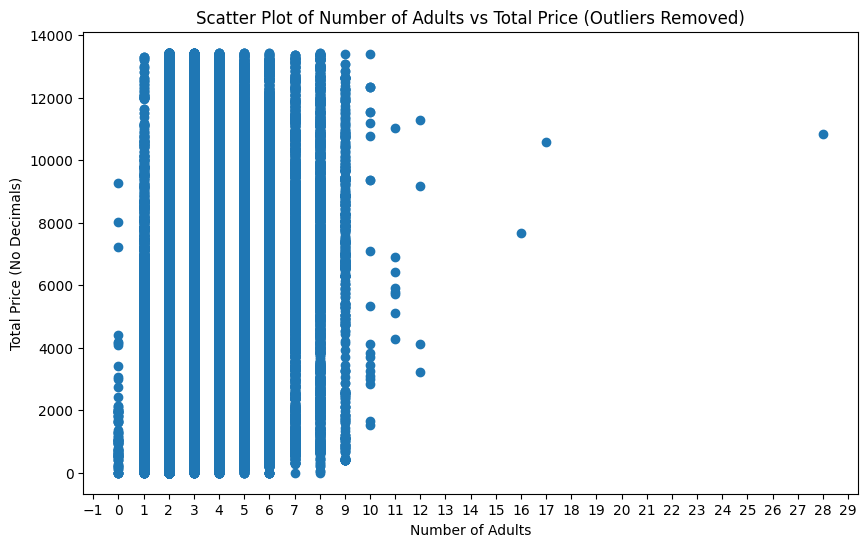

In [ ]:
# prompt: make a scatter plot for the number of ADULTS in a booking vs the TOTAL_PRICE. Dont use decimal places for total price. and remove outliers. show 1,2,3,4 for x axis

import matplotlib.pyplot as plt

# Remove outliers (example: removing top and bottom 1%)
q_low = bookings_df["TOTAL_PRICE"].quantile(0.01)
q_hi  = bookings_df["TOTAL_PRICE"].quantile(0.99)
filtered_bookings_df = bookings_df[(bookings_df["TOTAL_PRICE"] < q_hi) & (bookings_df["TOTAL_PRICE"] > q_low)]

# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(filtered_bookings_df['ADULT'], filtered_bookings_df['TOTAL_PRICE'])
plt.xlabel('Number of Adults')
plt.ylabel('Total Price (No Decimals)')
plt.title('Scatter Plot of Number of Adults vs Total Price (Outliers Removed)')

# Set x-axis ticks to integers only
plt.xticks(range(-1, 30))

# Remove decimal places from y-axis labels
plt.gca().yaxis.set_major_formatter(plt.FormatStrFormatter('%.0f'))

plt.show()


In [ ]:
# prompt: Adult Cost and Price: Plot the adult cost (ADT_COST) and adult price (ADT_PRICE) over time. make it interactive. alsoyou the average price and cost

import pandas as pd
# Calculate average adult price and cost per booking
adult_price_cost_per_booking = bookings_df.groupby(['Year', 'Month'])[['ADT_PRICE', 'ADT_COST']].mean().reset_index()

# Create a 'Date' column for plotting
adult_price_cost_per_booking['Date'] = pd.to_datetime(adult_price_cost_per_booking[['Year', 'Month']].assign(DAY=1))

# Create an interactive line chart using Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(x=adult_price_cost_per_booking['Date'], y=adult_price_cost_per_booking['ADT_PRICE'], mode='lines', name='Average Adult Price'))
fig.add_trace(go.Scatter(x=adult_price_cost_per_booking['Date'], y=adult_price_cost_per_booking['ADT_COST'], mode='lines', name='Average Adult Cost'))

fig.update_layout(
    title='Average Adult Price and Cost per Booking Over Time',
    xaxis_title='Booking Date',
    yaxis_title='Value'
)

fig.show()


In [ ]:
# prompt: Child Cost and Price: Plot the child cost (CHD_COST) and child price (CHD_PRICE) over time. get the average

import pandas as pd
# Calculate average child price and cost per booking
child_price_cost_per_booking = bookings_df.groupby(['Year', 'Month'])[['CHD_PRICE', 'CHD_COST']].mean().reset_index()

# Create a 'Date' column for plotting
child_price_cost_per_booking['Date'] = pd.to_datetime(child_price_cost_per_booking[['Year', 'Month']].assign(DAY=1))

# Create an interactive line chart using Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(x=child_price_cost_per_booking['Date'], y=child_price_cost_per_booking['CHD_PRICE'], mode='lines', name='Average Child Price'))
fig.add_trace(go.Scatter(x=child_price_cost_per_booking['Date'], y=child_price_cost_per_booking['CHD_COST'], mode='lines', name='Average Child Cost'))

fig.update_layout(
    title='Average Child Price and Cost per Booking Over Time',
    xaxis_title='Booking Date',
    yaxis_title='Value'
)

fig.show()


In [ ]:
# prompt: Infant Cost and Price: Plot the infant cost (INF_COST) and infant price (INF_PRICE) over time. average

import pandas as pd
# Calculate average infant price and cost per booking
infant_price_cost_per_booking = bookings_df.groupby(['Year', 'Month'])[['INF_PRICE', 'INF_COST']].mean().reset_index()

# Create a 'Date' column for plotting
infant_price_cost_per_booking['Date'] = pd.to_datetime(infant_price_cost_per_booking[['Year', 'Month']].assign(DAY=1))

# Create an interactive line chart using Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(x=infant_price_cost_per_booking['Date'], y=infant_price_cost_per_booking['INF_PRICE'], mode='lines', name='Average Infant Price'))
fig.add_trace(go.Scatter(x=infant_price_cost_per_booking['Date'], y=infant_price_cost_per_booking['INF_COST'], mode='lines', name='Average Infant Cost'))

fig.update_layout(
    title='Average Infant Price and Cost per Booking Over Time',
    xaxis_title='Booking Date',
    yaxis_title='Value'
)

fig.show()


In [ ]:
# prompt: Adult Tax Cost: Plot the adult tax cost (ADT_TAX_COST) over time.

# Calculate total adult tax cost by booking date
adult_tax_cost_by_date = bookings_df.groupby('BOOKED_DATE')['ADT_TAX_COST'].sum().reset_index()

# Create an interactive line chart using Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(x=adult_tax_cost_by_date['BOOKED_DATE'],
                         y=adult_tax_cost_by_date['ADT_TAX_COST'],
                         mode='lines', name='Adult Tax Cost'))

fig.update_layout(
    title='Adult Tax Cost Over Time',
    xaxis_title='Booking Date',
    yaxis_title='Value'
)

fig.show()


In [ ]:
# prompt: Child Tax Cost: Plot the child tax cost (CHD_TAX_COST) over time.

# Calculate total child tax cost by booking date
child_tax_cost_by_date = bookings_df.groupby('BOOKED_DATE')['CHD_TAX_COST'].sum().reset_index()

# Create an interactive line chart using Plotly
fig = go.Figure()

fig.add_trace(go.Scatter(x=child_tax_cost_by_date['BOOKED_DATE'],
                         y=child_tax_cost_by_date['CHD_TAX_COST'],
                         mode='lines', name='Child Tax Cost'))

fig.update_layout(
    title='Child Tax Cost Over Time',
    xaxis_title='Booking Date',
    yaxis_title='Value'
)

fig.show()


In [ ]:
# prompt: show the highest values of TOTAL_PRICE, PRICE

# Highest TOTAL_PRICE
print("Highest Total Price:", bookings_df['TOTAL_PRICE'].max())

# Highest PRICE (assuming this refers to a column in either bookings_df or sector_df)
if 'PRICE' in bookings_df.columns:
  print("Highest Price (bookings_df):", bookings_df['PRICE'].max())
elif 'PRICE' in sector_df.columns:
  print("Highest Price (sector_df):", sector_df['PRICE'].max())
else:
  print("No 'PRICE' column found in either DataFrame.")


Highest Total Price: 20002016.1
Highest Price (bookings_df): 121102.83


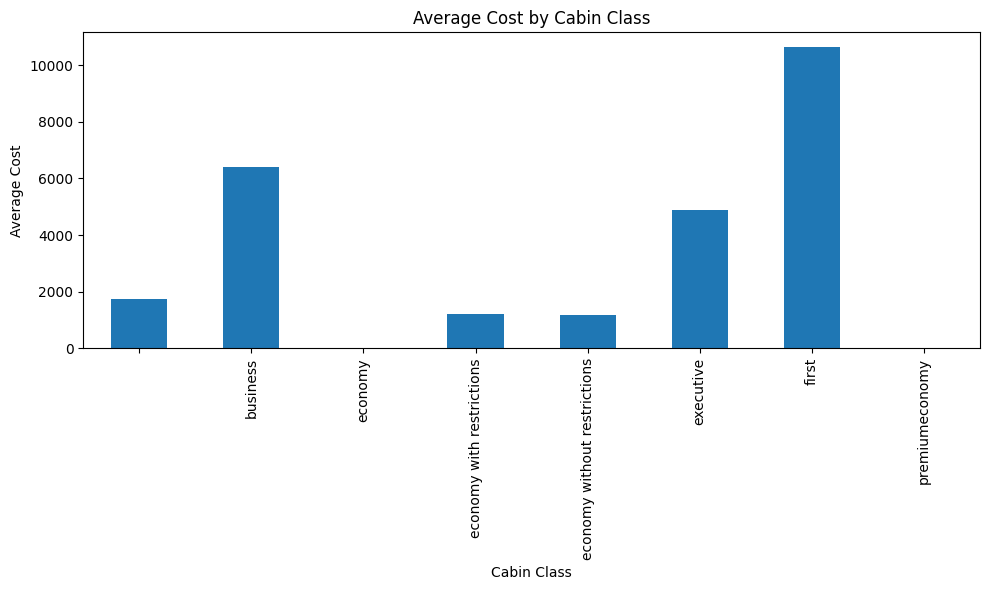

In [ ]:
import matplotlib.pyplot as plt

# Calculate average cost per cabin class
average_cost_by_cabin = bookings_df.groupby('BOOKING_ID')['COST'].mean()
cabin_cost = sector_df.groupby('CABIN_CLASS')['BOOKING_ID'].apply(lambda x: average_cost_by_cabin.get(x.values).mean() if average_cost_by_cabin.get(x.values) is not None else 0) # Added conditional to handle None values

# Create bar plot
plt.figure(figsize=(10, 6))
cabin_cost.plot(kind='bar')
plt.xlabel('Cabin Class')
plt.ylabel('Average Cost')
plt.title('Average Cost by Cabin Class')
plt.xticks(rotation=90)  # Rotate x-axis labels if needed
plt.tight_layout()
plt.show()

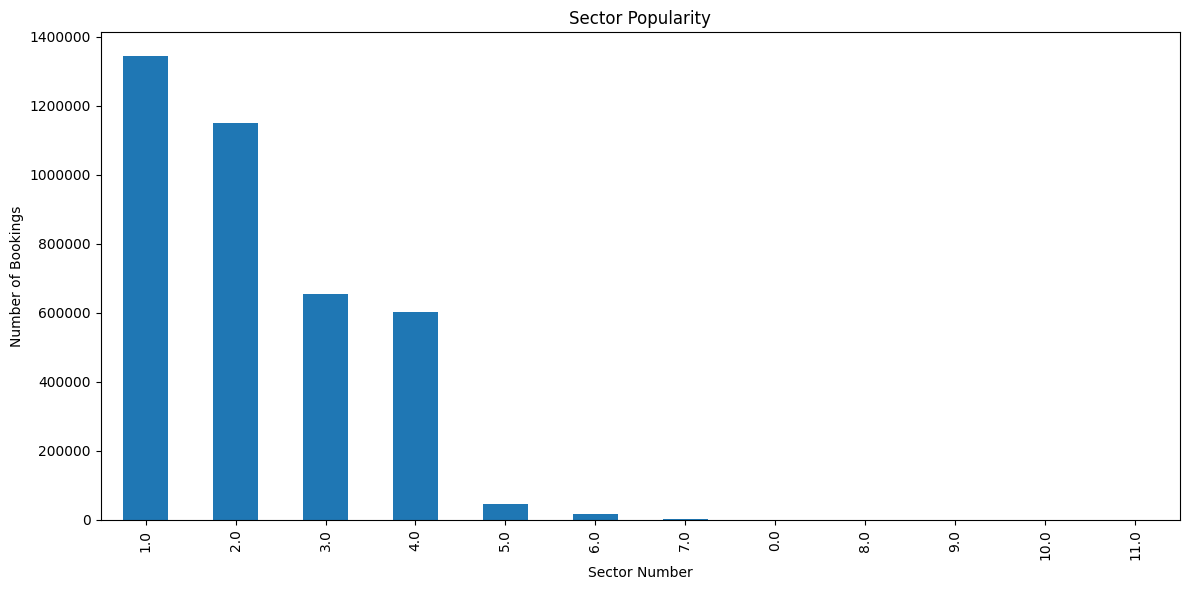

In [ ]:
# prompt: Bar Chart:
# Product Code Popularity: x-axis (PRODUCT_CODE), y-axis (count of BOOKING_ID). remove the scientific notation

import matplotlib.pyplot as plt
# Count bookings for each product code
product_popularity = sector_df['SECTOR_NO'].value_counts()

# Create bar chart
plt.figure(figsize=(12, 6))
product_popularity.plot(kind='bar')
plt.xlabel('Sector Number')
plt.ylabel('Number of Bookings')
plt.title('Sector Popularity')
plt.xticks(rotation=90)

# Remove scientific notation from y-axis
plt.gca().get_yaxis().get_major_formatter().set_scientific(False)

plt.tight_layout()
plt.show()



In [ ]:
# prompt: Line Graph:
# Airline Trends: x-axis (BOOKED_DATE), y-axis (count of BOOKING_ID), color/group by AIRLINE. Theres alot of airlines its gonna be hard to find which is which, so how can you avoid it? Make it so i can zoom in

import plotly.express as px

# Group by airline and booking date, count bookings
airline_trends = sector_df.groupby(['AIRLINE', 'BOOKED_DATE'])['BOOKING_ID'].count().reset_index()

# Create interactive line plot with Plotly
fig = px.line(airline_trends, x='BOOKED_DATE', y='BOOKING_ID', color='AIRLINE',
              title='Airline Trends Over Time')

# Customize layout for better readability and zooming
fig.update_layout(
    xaxis_title='Booking Date',
    yaxis_title='Number of Bookings',
    legend_title='Airline',
    legend=dict(x=1, y=1, xanchor='right', yanchor='top'),  # Place legend outside plot area
    hovermode='closest'  # Show data on hover
)

# Add range slider for zooming
fig.update_xaxes(rangeslider_visible=True)

fig.show()


In [ ]:
# prompt: Departure Date Analysis: Plot the number of bookings (BOOKING_ID) for each DEP_DATE to observe seasonality and peak times. show x axis only from 2017 to 2026. use a histogram. show months between years

import pandas as pd
# Convert 'DEP_DATE' to datetime, handling potential errors
sector_df['DEP_DATE'] = pd.to_datetime(sector_df['DEP_DATE'], errors='coerce', format='%Y-%m-%d')

# Filter data for years 2017 to 2026
filtered_df = sector_df[(sector_df['DEP_DATE'].dt.year >= 2017) & (sector_df['DEP_DATE'].dt.year <= 2026)]

# Group by departure date and count bookings
bookings_by_dep_date = filtered_df.groupby('DEP_DATE')['BOOKING_ID'].count().reset_index()

# Create histogram with Plotly
fig = px.histogram(bookings_by_dep_date, x='DEP_DATE', y='BOOKING_ID', nbins=200,
                   title='Number of Bookings by Departure Date (2019-2026)')

# Customize layout
fig.update_layout(
    xaxis_title='Departure Date',
    yaxis_title='Number of Bookings',
    xaxis_range=[pd.to_datetime('2019-01-01'), pd.to_datetime('2026-12-31')],
    bargap=0.1
)

fig.show()


Note : The downhill slope from 2020 to 2021 july probably due to lockdown

In [ ]:
# prompt: Destination Date Analysis: Plot the number of bookings (BOOKING_ID) for each DES_DATE. Use a histogram from 2018 to 2025

import pandas as pd
# Group by destination date and count bookings
destination_trends = sector_df.groupby('DES_DATE')['BOOKING_ID'].count().reset_index()

# Convert DES_DATE to datetime and extract year
destination_trends['DES_DATE'] = pd.to_datetime(destination_trends['DES_DATE'])
destination_trends['Year'] = destination_trends['DES_DATE'].dt.year

# Filter data for years 2018 to 2025
filtered_destinations = destination_trends[(destination_trends['Year'] >= 2018) & (destination_trends['Year'] <= 2026)]

# Create histogram with Plotly
fig = px.histogram(filtered_destinations, x='DES_DATE', y='BOOKING_ID',
                   title='Destination Trends Over Time (2018-2025)',
                   nbins=100) # Adjust number of bins as needed

# Customize layout
fig.update_layout(
    xaxis_title='Destination Date',
    yaxis_title='Number of Bookings',
    bargap=0.1  # Adjust spacing between bars
)

fig.show()


<ipython-input-37-d0434b46c480>:8: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



In [ ]:

# Booking Status Trends
booking_status_trends = bookings_df.groupby(['BOOKING_STATUS'])['BOOKING_ID'].count().reset_index(name='count')
fig = px.bar(booking_status_trends, x='BOOKING_STATUS', y='count', color='BOOKING_STATUS',
              title='Total Bookings by Status')
fig.update_layout(xaxis_title='Booking Status', yaxis_title='Number of Bookings')
fig.show()

In [ ]:
# Option Status Trends
option_status_trends = bookings_df.groupby(['OPTION_STATUS'])['BOOKING_ID'].count().reset_index(name='count')
fig = px.bar(option_status_trends, x='OPTION_STATUS', y='count', color='OPTION_STATUS',
              title='Option Status')
fig.update_layout(xaxis_title='Option Status', yaxis_title='Number of Bookings', legend_title='Option Status')
fig.show()


In [ ]:
# Booking Item Status Trends
booking_item_status_trends = bookings_df.groupby(['BOOKING_ITEM_STATUS'])['BOOKING_ID'].count().reset_index(name='count')
fig = px.bar(booking_item_status_trends, x='BOOKING_ITEM_STATUS', y='count', color='BOOKING_ITEM_STATUS',
              title='Booking Item Status')
fig.update_layout(xaxis_title='Booking Item Status', yaxis_title='Number of Bookings')
fig.show()

In [ ]:
# prompt: Fare Type Trends: Plot the number of bookings (BOOKING_ID) for each FARE_TYPE over time.

# Fare Type Trends
fare_type_trends = bookings_df.groupby(['FARE_TYPE', 'BOOKED_DATE'])['BOOKING_ID'].count().reset_index()
fig = px.line(fare_type_trends, x='BOOKED_DATE', y='BOOKING_ID', color='FARE_TYPE',
              title='Fare Type Trends Over Time')
fig.update_layout(xaxis_title='Booking Date', yaxis_title='Number of Bookings', legend_title='Fare Type')
fig.show()



In [ ]:
# prompt: CRS Trends: Plot the number of bookings (BOOKING_ID) for each CRS over time.

# CRS Trends
crs_trends = bookings_df.groupby(['CRS', 'BOOKED_DATE'])['BOOKING_ID'].count().reset_index()
fig = px.line(crs_trends, x='BOOKED_DATE', y='BOOKING_ID', color='CRS',
              title='CRS Trends Over Time')
fig.update_layout(xaxis_title='Booking Date', yaxis_title='Number of Bookings', legend_title='CRS')
fig.show()



In [ ]:
# prompt: plot of AIRLINE and CABIN_CLASS with no of bookings over 4000

# Group by airline and cabin class, count bookings
airline_cabin_bookings = sector_df.groupby(['AIRLINE', 'CABIN_CLASS'])['BOOKING_ID'].count().reset_index()

# Filter for bookings over 4000
popular_routes = airline_cabin_bookings[airline_cabin_bookings['BOOKING_ID'] > 4000]

# Create bar plot using Plotly
fig = px.bar(popular_routes, x='AIRLINE', y='BOOKING_ID', color='CABIN_CLASS',
             title='Popular Airlines (Bookings > 4000)',
             labels={'BOOKING_ID': 'Number of Bookings'})

fig.update_layout(xaxis_title='Airline', yaxis_title='Number of Bookings', legend_title='Cabin Class')
fig.show()


As there are too many airlines, only the ones with more than 4000 bookings were taken.

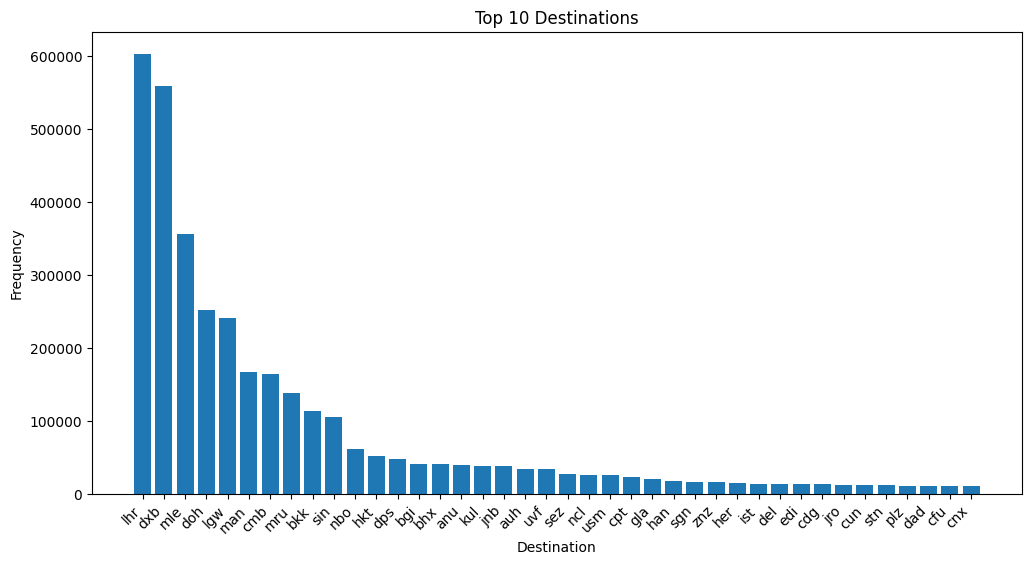

In [ ]:
# Top 10 destinations
top_destinations = sector_df['DES'].value_counts().nlargest(40)
plt.figure(figsize=(12, 6))
plt.bar(top_destinations.index, top_destinations.values)
plt.xlabel('Destination')
plt.ylabel('Frequency')
plt.title('Top 10 Destinations')
plt.xticks(rotation=45, ha='right')
plt.show()

# **Correlation Analysis**

In [ ]:
# prompt: can you plot the correlation matrix. make it interacctive and the plot bigger

import plotly.figure_factory as ff

# Calculate correlation matrix
correlation_matrix = bookings_df.select_dtypes(include=['number']).corr() # Select only numeric columns

# Create interactive heatmap using Plotly
fig = ff.create_annotated_heatmap(
    z=correlation_matrix.values,
    x=correlation_matrix.columns.tolist(),
    y=correlation_matrix.columns.tolist(),
    colorscale='Viridis',  # Choose a color scale
    annotation_text=correlation_matrix.round(2).values,  # Display rounded correlation values
    showscale=True
)

# Increase plot size
fig.update_layout(
    title='Correlation Matrix',
    width=1500,  # Adjust width as needed
    height=1500,  # Adjust height as needed
)

fig.show()


In [ ]:
# Calculate correlation with 'TOTAL_PRICE'
price_correlations = bookings_df.select_dtypes(include=['number']).corr()['TOTAL_PRICE'].sort_values(ascending=False).round(2) # Select only numeric columns before calculating correlation

# Print correlations in descending order
print(price_correlations)

TOTAL_PRICE               1.00
TOTAL_COST                0.17
TOTAL_COST_IN_CONTRACT    0.13
PRICE                     0.12
COST                      0.12
ADT_PRICE                 0.10
ADT_COST                  0.10
COST_IN_CONTRACT          0.08
BOOKING_ITEM_STATUS       0.07
ADT_TAX_COST              0.06
CHD_PRICE                 0.06
CHD_COST                  0.05
CHD_TAX_COST              0.05
ADULT                     0.05
CHILD                     0.03
INF_PRICE                 0.02
INF_TAX_COST              0.02
BOOKING_ID                0.01
Year                      0.01
INFANT                    0.01
INF_COST                  0.01
Month                    -0.00
ITEM_NO                  -0.01
BOOKING_STATUS           -0.03
OPTION_STATUS            -0.06
Name: TOTAL_PRICE, dtype: float64


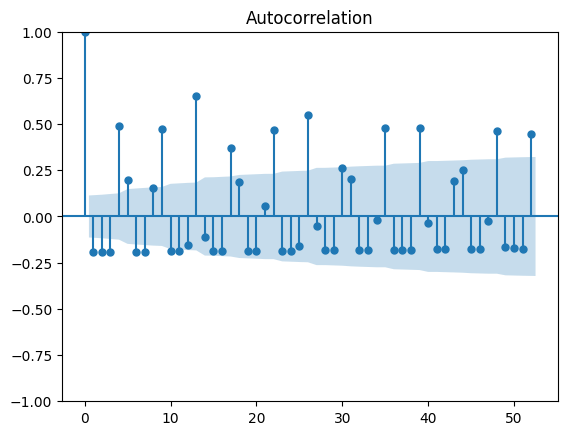

In [ ]:
# prompt: ACF (Autocorrelation Function): Plot ACF to identify the correlation of the time series with its own lagged values. theres too many records so its taking too much time

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Resample to a less granular frequency (e.g., weekly)
bookings_weekly = bookings_by_time.set_index('Date').resample('W').sum()

# Plot ACF with a limited number of lags
plot_acf(bookings_weekly['TOTAL_PRICE'], lags=52)  # Plot for 52 weeks (1 year)
plt.show()


<Figure size 1200x600 with 0 Axes>

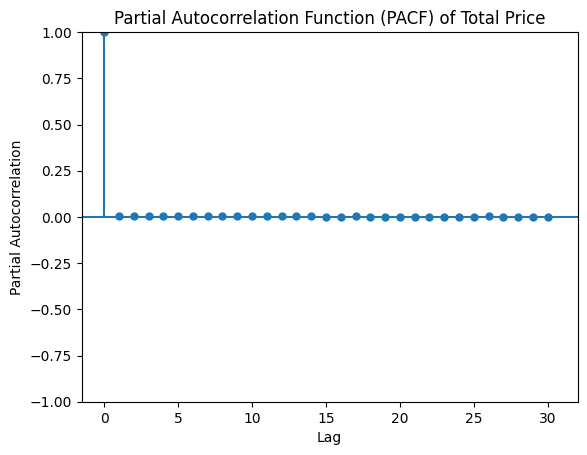

In [ ]:
# prompt: PACF (Partial Autocorrelation Function): Plot PACF to identify the correlation of the time series with its own lagged values, controlling for the values of the time series at all shorter lags.

import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_pacf

# Assuming 'bookings_daily' is your time series DataFrame
# Extract the 'TOTAL_PRICE' column as a Series
total_price_series = bookings_df['TOTAL_PRICE']

# Plot the PACF
plt.figure(figsize=(12, 6))
plot_pacf(total_price_series, lags=30)  # Adjust 'lags' to control the number of lags shown
plt.xlabel('Lag')
plt.ylabel('Partial Autocorrelation')
plt.title('Partial Autocorrelation Function (PACF) of Total Price')
plt.show()


# **Stationarity Check**

In [ ]:
# prompt: do the ADF test to check for stationarity. theres too many records so the session crashes avoid this

from statsmodels.tsa.stattools import adfuller

# Sample the data to reduce the number of records
sampled_bookings = bookings_df.sample(frac=0.1, random_state=42)  # Adjust 'frac' to control the sampling fraction

# Extract the 'TOTAL_PRICE' column from the sampled data
total_price_series_sampled = sampled_bookings['TOTAL_PRICE']

# Perform the ADF test on the sampled data
result = adfuller(total_price_series_sampled)

# Print the test results
print('ADF Statistic:', result[0])
print('p-value:', result[1])
print('Critical Values:')
for key, value in result[4].items():
  print('\t%s: %.3f' % (key, value))

# Interpret the results
if result[1] <= 0.05:
  print('The time series is likely stationary.')
else:
  print('The time series is likely non-stationary.')


ADF Statistic: -260.333755587257
p-value: 0.0
Critical Values:
	1%: -3.430
	5%: -2.862
	10%: -2.567
The time series is likely stationary.


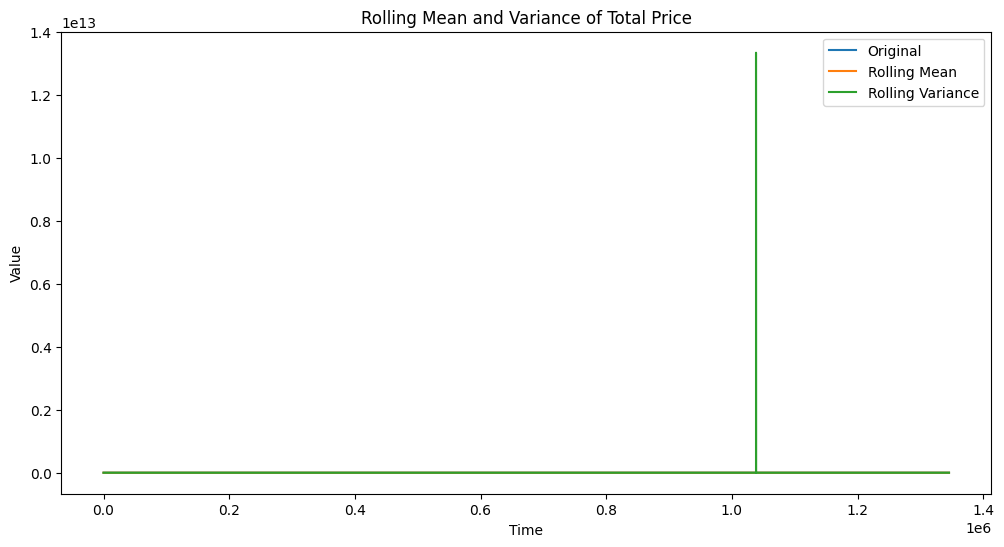

In [ ]:
# prompt: Plot rolling statistics (mean, variance) to visually inspect stationarity avoid session crashing again

import matplotlib.pyplot as plt
# Calculate rolling mean and variance
rolling_mean = total_price_series.rolling(window=30).mean()  # Adjust window as needed
rolling_var = total_price_series.rolling(window=30).var()

# Plot rolling statistics
plt.figure(figsize=(12, 6))
plt.plot(total_price_series, label='Original')
plt.plot(rolling_mean, label='Rolling Mean')
plt.plot(rolling_var, label='Rolling Variance')
plt.xlabel('Time')
plt.ylabel('Value')
plt.title('Rolling Mean and Variance of Total Price')
plt.legend()
plt.show()
